<div style="font-family:'Times New Roman',Times,serif;color:#000000">
<div style="font-size:13px;letter-spacing:2px">NATIONAL UNIVERSITY OF SCIENCES AND TECHNOLOGY &nbsp;&middot;&nbsp; SEECS</div>
<div style="font-size:13px;letter-spacing:1px;font-weight:bold">CS-320 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:28px;font-weight:bold;margin-top:6px">Lab 11 &mdash; Convolutional Neural Networks: Layers and How They Work</div>
<div style="font-size:15px;margin-top:4px">3 hours</div>
</div>

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain / 502808

### What this lab is for

So far our networks took a list of numbers as input. **Images** are different: a pixel is related to
the pixels around it, and an object can appear anywhere in the picture. A **convolutional neural
network (CNN)** is built for exactly this. In this lab you will learn what each CNN layer
(**convolution, ReLU, max pooling, flatten, linear**) does, first by writing the operations **by
hand** on tiny examples, and then by building a small CNN in PyTorch that recognises pieces of
clothing in the **Fashion-MNIST** images.

Every idea is explained before the task, and the code is short.

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab11_<yourCMSID>.ipynb` before uploading to LMS.

</div>


## Task 0 &mdash; Setup and data

> **The dataset.** **Fashion-MNIST** has 70,000 grey-scale images of 28 x 28 pixels, in 10 classes of clothing:
> T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot. PyTorch downloads
> it for you.
> Source: https://github.com/zalandoresearch/fashion-mnist
> (PyTorch documentation: https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html)

**Task 0.1.** Run the cells below. The first one imports the libraries, the second one loads the data (60,000
training images, of which 5,000 are kept for validation, and 10,000 test images), the third one shows
some images.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(0); np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "  device:", device)


PyTorch: 2.15.0+cpu   device: cpu


In [2]:
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=tf)
train_set, val_set = random_split(full_train, [55000, 5000], generator=torch.Generator().manual_seed(0))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128)
test_loader = DataLoader(test_set, batch_size=128)
print("train:", len(train_set), " validation:", len(val_set), " test:", len(test_set))


train: 55000  validation: 5000  test: 10000


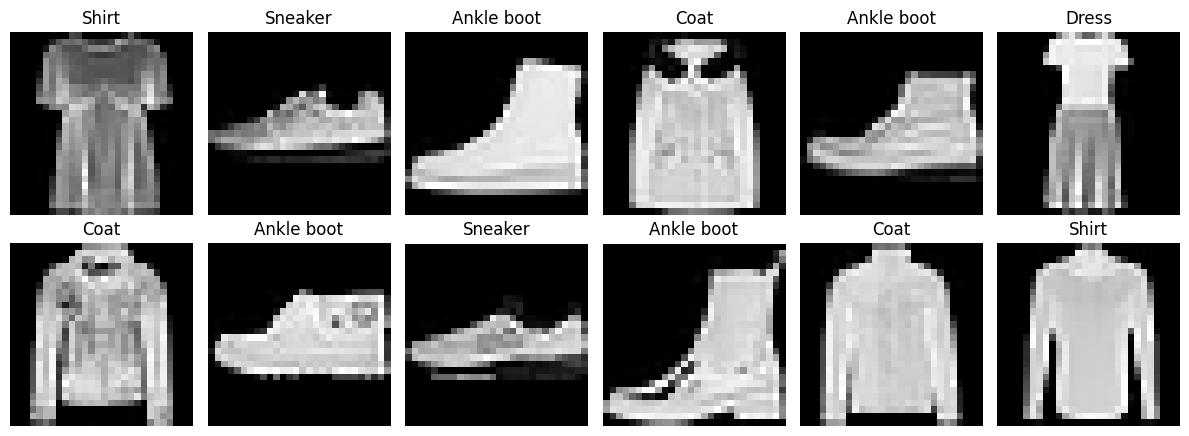

one image has the shape (1, 28, 28)  = (channels, height, width)


In [3]:
fig, ax = plt.subplots(2, 6, figsize=(12, 4.5))
for a, i in zip(ax.ravel(), range(12)):
    image, label = train_set[i]
    a.imshow(image.squeeze(), cmap="gray"); a.set_title(CLASSES[label]); a.axis("off")
plt.tight_layout(); plt.show()
image, label = train_set[0]
print("one image has the shape", tuple(image.shape), " = (channels, height, width)")


## Task 1 &mdash; The convolution by hand

> **Concept.** We use a tiny 5 x 5 "image" whose left part is dark (0) and right part is bright (1), and a 3 x 3
> filter that detects **vertical edges** (dark on the left, bright on the right). The filter has the weights
> `[-1, 0, 1]` in each row.

**Task 1.1 (by hand).** On paper, place the filter on the top-left 3 x 3 patch of the image and compute the first
output number (multiply and add). Write it as a comment. Then compute the whole output by hand if you want.

**Task 1.2.** Complete `conv2d_manual(image, kernel)`: for every position `(i, j)` the output is the sum of
`image[i:i+k, j:j+k] * kernel`. (No padding, stride 1. The output has the size `n - k + 1`.) Then the cell compares your result
with PyTorch's `F.conv2d`.

**Task 1.3.** Apply your function to a **real** image with a vertical-edge filter and a horizontal-edge filter,
and look at the two feature maps.


In [4]:
img = np.array([[0, 0, 1, 1, 1]] * 5, dtype=float)            # dark on the left, bright on the right
kernel = np.array([[-1, 0, 1]] * 3, dtype=float)             # vertical-edge filter

# TODO 1.1 — the first output number, worked out by hand:
# Top-left 3x3 patch: [[0, 0, 1], [0, 0, 1], [0, 0, 1]]
# Kernel:             [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]
# First output number = 3 * (0*(-1) + 0*0 + 1*1) = 3 * 1 = 3.0
# Full 3x3 output by hand: [[3, 3, 0], [3, 3, 0], [3, 3, 0]]

def conv2d_manual(image, kernel):
    k = kernel.shape[0]
    out_h, out_w = image.shape[0] - k + 1, image.shape[1] - k + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            # TODO 1.2 — out[i, j] = sum of (the k x k patch of the image at (i, j)) * kernel
            out[i, j] = np.sum(image[i:i+k, j:j+k] * kernel)
    return out

mine = conv2d_manual(img, kernel)
print("my output (3 x 3):\n", mine)
torch_out = F.conv2d(torch.tensor(img).reshape(1, 1, 5, 5).float(), torch.tensor(kernel).reshape(1, 1, 3, 3).float())
print("matches F.conv2d:", np.allclose(mine, torch_out.squeeze().numpy()))


my output (3 x 3):
 [[3. 3. 0.]
 [3. 3. 0.]
 [3. 3. 0.]]
matches F.conv2d: True


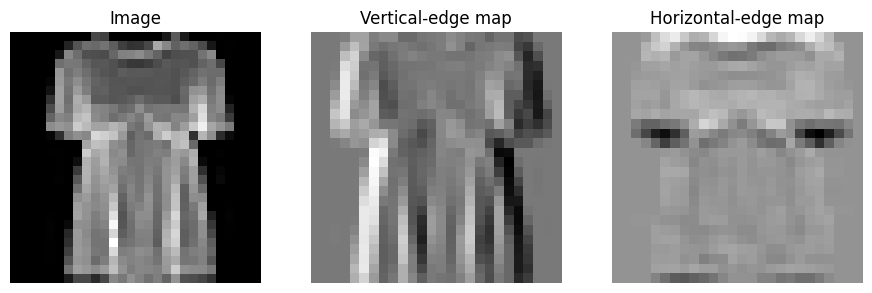

In [5]:
real = train_set[0][0].squeeze().numpy()               # a 28 x 28 image
k_vertical = np.array([[-1, 0, 1]] * 3, dtype=float)
k_horizontal = k_vertical.T

# TODO 1.3 — vertical = conv2d_manual(real, k_vertical);  horizontal = conv2d_manual(real, k_horizontal)
vertical = conv2d_manual(real, k_vertical)
horizontal = conv2d_manual(real, k_horizontal)

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for a, im, t in zip(ax, [real, vertical, horizontal], ["Image", "Vertical-edge map", "Horizontal-edge map"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()

# Task 1 answers:
# Q1 (a 5 x 5 image and a 3 x 3 filter give a 3 x 3 output: why? what is the output where the image is constant?):
# Answer: With no padding (p = 0) and stride s = 1, a 3 x 3 filter can be placed at n - k + 1 = 5 - 3 + 1 = 3
# valid positions horizontally and 3 vertically without going past the image border, giving a 3 x 3 output.
# Where the image is constant (all pixels equal to c), the output is 0 because the kernel weights sum to zero:
# 3 * (c*(-1) + c*0 + c*1) = 0.
# Q2 (what does the vertical-edge map show for your image, and what does the horizontal-edge map show?):
# Answer: For this T-shirt/top image, the vertical-edge map highlights vertical boundaries where intensity
# changes left-to-right: bright along the left outer edge of the sleeve and torso (dark-to-bright) and dark
# along the right outer edge (bright-to-dark), while flat regions appear neutral gray (0). The horizontal-edge
# map highlights horizontal boundaries: bright along the top collar/shoulders and dark along the underside of
# the sleeves and bottom hem, while vertical edges and uniform interiors fade to neutral gray.


## Task 2 &mdash; ReLU and max pooling by hand

> **Concept.** Take a 4 x 4 feature map with positive and negative numbers. ReLU replaces every negative number
> by 0. Max pooling then keeps the largest number of every 2 x 2 block, so the 4 x 4 map becomes 2 x 2.

**Task 2.1.** Apply ReLU to the feature map `fm` with `np.maximum(0, fm)`.

**Task 2.2.** Complete `max_pool_manual(x, size=2)`: the output at `(i, j)` is the maximum of the block
`x[i*size:(i+1)*size, j*size:(j+1)*size]`. Compare with PyTorch's `F.max_pool2d`.


In [6]:
fm = np.array([[ 1, -2,  3,  0],
               [ 4,  5, -6,  1],
               [-1,  2,  0,  3],
               [ 2, -3,  1,  4]], dtype=float)

# TODO 2.1 — relu_fm = ...
relu_fm = np.maximum(0, fm)
print("after ReLU:\n", relu_fm)

def max_pool_manual(x, size=2):
    out = np.zeros((x.shape[0] // size, x.shape[1] // size))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            # TODO 2.2 — the maximum of the size x size block of x that belongs to (i, j)
            out[i, j] = np.max(x[i*size:(i+1)*size, j*size:(j+1)*size])
    return out

pooled = max_pool_manual(relu_fm)
print("after max pooling:\n", pooled)
torch_pool = F.max_pool2d(torch.tensor(relu_fm).reshape(1, 1, 4, 4), 2)
print("matches F.max_pool2d:", np.allclose(pooled, torch_pool.squeeze().numpy()))

# Task 2 answers:
# Q1 (do ReLU and max pooling have parameters that are learned? what does each of them do to the feature map?):
# Answer: No, neither ReLU nor max pooling has any learnable parameters (0 parameters each). ReLU applies
# max(0, x) element-wise to add non-linearity and zero out negative values while keeping the same shape.
# Max pooling keeps only the maximum value from each 2 x 2 block, halving both the height and width of the map.
# Q2 (what information is lost by max pooling, and why is this acceptable?):
# Answer: Max pooling discards the non-maximum activations and the exact pixel position of the maximum inside
# each 2 x 2 block. This is acceptable (and useful) because knowing whether a pattern is present in a local
# neighbourhood matters more than its exact pixel coordinate; it provides local translation invariance and
# reduces spatial size and computation for subsequent layers.


after ReLU:
 [[1. 0. 3. 0.]
 [4. 5. 0. 1.]
 [0. 2. 0. 3.]
 [2. 0. 1. 4.]]
after max pooling:
 [[5. 3.]
 [2. 4.]]
matches F.max_pool2d: True


## Task 3 &mdash; Shapes and parameters of every layer

> **Concept.** Most mistakes with CNNs are shape mistakes, so we always check the shape after every layer. The two
> formulas of the Background section tell us the output size and the number of parameters of a layer
> **before** we run anything.

**Task 3.1.** Complete `conv_output_size(n, k, p, s)` with the formula `(n - k + 2p) // s + 1`, and
`conv_params(c_in, c_out, k)` with the formula `(k*k*c_in + 1) * c_out`. The provided tests check them.

**Task 3.2.** The cell builds the layers of our network. Run an image through them and read the printed shape and
the number of parameters of every layer. Compare with the table of the Background and with your two functions.

**Task 3.3.** Count the parameters of a normal network for the same job,
`Flatten -> Linear(784, 128) -> ReLU -> Linear(128, 10)`, and compare it with the CNN.


In [7]:
def conv_output_size(n, k, p=0, s=1):
    # TODO 3.1 — (n - k + 2p) // s + 1
    return (n - k + 2 * p) // s + 1

def conv_params(c_in, c_out, k):
    # TODO 3.1 — (k * k * c_in + 1) * c_out
    return (k * k * c_in + 1) * c_out

assert conv_output_size(28, 3, 1, 1) == 28 and conv_output_size(28, 3, 0, 1) == 26
assert conv_output_size(28, 2, 0, 2) == 14
assert conv_params(1, 8, 3) == 80 and conv_params(8, 16, 3) == 1168
print("formula tests passed")


formula tests passed


In [8]:
layers = [
    ("Conv2d(1, 8, 3, padding=1)", nn.Conv2d(1, 8, kernel_size=3, padding=1)),
    ("ReLU", nn.ReLU()),
    ("MaxPool2d(2)", nn.MaxPool2d(2)),
    ("Conv2d(8, 16, 3, padding=1)", nn.Conv2d(8, 16, kernel_size=3, padding=1)),
    ("ReLU", nn.ReLU()),
    ("MaxPool2d(2)", nn.MaxPool2d(2)),
    ("Flatten", nn.Flatten()),
    ("Linear(784, 10)", nn.Linear(16 * 7 * 7, 10)),
]
x = train_set[0][0].unsqueeze(0)                      # one image: (1, 1, 28, 28) = (batch, channels, height, width)
print(f"{'layer':30s} {'output shape':22s} parameters")
print(f"{'input':30s} {str(tuple(x.shape)):22s} 0")
for name, layer in layers:
    x = layer(x)
    n_params = sum(p.numel() for p in layer.parameters())
    print(f"{name:30s} {str(tuple(x.shape)):22s} {n_params}")
total = sum(sum(p.numel() for p in layer.parameters()) for _, layer in layers)
print("total parameters of the CNN:", total)

# TODO 3.3 — mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)); count its parameters
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
mlp_total = sum(p.numel() for p in mlp.parameters())
print("total parameters of the normal MLP:", mlp_total)
print(f"MLP has {mlp_total / total:.2f}x more parameters than the CNN")

# Task 3 answers:
# Q1 (which layer has the most parameters? which layers have none?):
# Answer: Linear(784, 10) has the most parameters (7,850 out of 9,098, about 86.3% of the model).
# The ReLU, MaxPool2d(2), and Flatten layers have 0 parameters.
# Q2 (why does the CNN need far fewer parameters than the normal network? think of "shared weights" and "small patches"):
# Answer: A normal MLP assigns a separate weight from every input pixel to every hidden unit
# (784 * 128 + 128 = 100,480 parameters in the first layer alone, 101,770 total). A CNN instead uses small
# local 3 x 3 filters whose weights are shared across every position in the image (only 80 parameters for
# conv1 and 1,168 for conv2), and pooling shrinks the spatial dimensions before the final linear layer,
# keeping the total to just 9,098 parameters (~11.2x fewer).


layer                          output shape           parameters
input                          (1, 1, 28, 28)         0
Conv2d(1, 8, 3, padding=1)     (1, 8, 28, 28)         80
ReLU                           (1, 8, 28, 28)         0
MaxPool2d(2)                   (1, 8, 14, 14)         0
Conv2d(8, 16, 3, padding=1)    (1, 16, 14, 14)        1168
ReLU                           (1, 16, 14, 14)        0
MaxPool2d(2)                   (1, 16, 7, 7)          0
Flatten                        (1, 784)               0
Linear(784, 10)                (1, 10)                7850
total parameters of the CNN: 9098
total parameters of the normal MLP: 101770
MLP has 11.19x more parameters than the CNN


## Task 4 &mdash; Build the CNN as an `nn.Module`

**Task 4.1.** Complete the class `SimpleCNN`. In `__init__` create `self.conv1 = nn.Conv2d(1, 8, 3, padding=1)`,
`self.conv2 = nn.Conv2d(8, 16, 3, padding=1)`, `self.pool = nn.MaxPool2d(2)`, `self.relu = nn.ReLU()` and
`self.fc = nn.Linear(16 * 7 * 7, 10)`. In `forward`, apply: conv1, ReLU, pool, conv2, ReLU, pool, flatten
(`x.flatten(1)`), fc. The output is the 10 class scores (no softmax: the loss will do it).

**Task 4.2.** Create the model, print it, check that a batch of 4 images gives the output shape `(4, 10)`, and that
the number of parameters is the same as in Task 3.


In [9]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO 4.1 — conv1, conv2, pool, relu, fc
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.fc = nn.Linear(16 * 7 * 7, 10)

    def forward(self, x):
        # TODO 4.1 — conv1 -> relu -> pool -> conv2 -> relu -> pool -> flatten -> fc
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.flatten(1)
        return self.fc(x)

# TODO 4.2 — model = SimpleCNN().to(device); print(model); the output shape for 4 images; the parameter count
model = SimpleCNN().to(device)
print(model)
sample_batch = torch.randn(4, 1, 28, 28, device=device)
print("output shape for 4 images:", tuple(model(sample_batch).shape))
print("total parameters:", sum(p.numel() for p in model.parameters()))


SimpleCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc): Linear(in_features=784, out_features=10, bias=True)
)
output shape for 4 images: (4, 10)
total parameters: 9098


## Task 5 &mdash; Training and testing

> **Concept.** Training is the same loop as in Lab 9: forward, loss, backward, update. The loss is
> `nn.CrossEntropyLoss` (it takes the 10 scores and the true class). The helper `run_epoch` runs one pass
> over a loader and returns the average loss and the accuracy; it trains if an optimiser is given.

**Task 5.1.** Create `criterion = nn.CrossEntropyLoss()` and `optimizer = torch.optim.Adam(model.parameters(), lr=0.001)`.

**Task 5.2.** Train for 3 epochs: in every epoch call `run_epoch` on the training loader (with the optimiser) and
on the validation loader (without it), store the numbers in `history`, and print one line.

**Task 5.3.** Plot the curves with the provided cell, and then evaluate **once** on the test loader.


In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over a loader. Trains if an optimiser is given. Returns (average loss, accuracy in %)."""
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(training):
            scores = model(x)
            loss = criterion(scores, y)
        if training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (scores.argmax(dim=1) == y).sum().item()
        count += len(y)
    return total_loss / count, 100 * correct / count

criterion = nn.CrossEntropyLoss()      # TODO 5.1
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)      # TODO 5.1
epochs = 3
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

# TODO 5.2 — for epoch in range(1, epochs + 1): run_epoch on train_loader (with optimizer) and on val_loader (without),
#            append the four numbers to history, and print a line
for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader, criterion)
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    print(f"Epoch {epoch}/{epochs} | train loss: {tr_loss:.4f}, train acc: {tr_acc:.2f}% | val loss: {va_loss:.4f}, val acc: {va_acc:.2f}%")


Epoch 1/3 | train loss: 0.5790, train acc: 79.86% | val loss: 0.4020, val acc: 85.14%


Epoch 2/3 | train loss: 0.3728, train acc: 86.68% | val loss: 0.3474, val acc: 87.34%


Epoch 3/3 | train loss: 0.3317, train acc: 88.30% | val loss: 0.3240, val acc: 88.24%


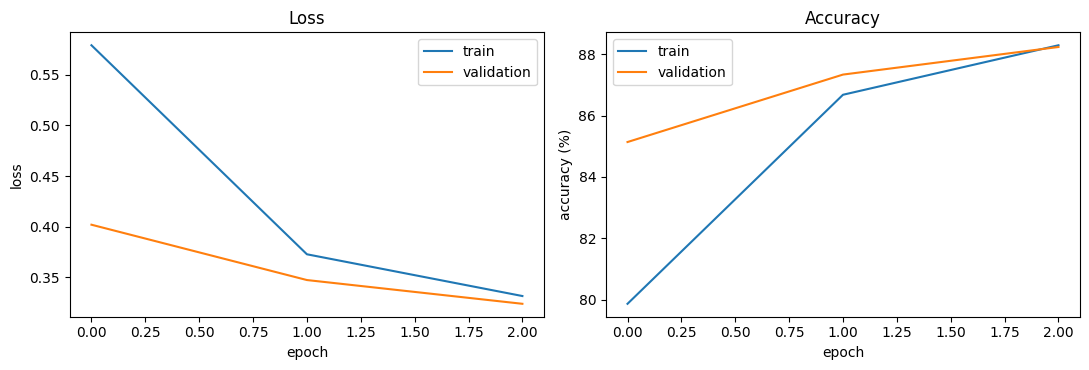

Test loss: 0.3472 | Test accuracy: 87.24%


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="validation")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy (%)"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

# TODO 5.3 — test_loss, test_acc = run_epoch(model, test_loader, criterion); print them
test_loss, test_acc = run_epoch(model, test_loader, criterion)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2f}%")

# Task 5 answers:
# Q1 (report the test accuracy. Do the training and validation curves stay close?):
# Answer: The test accuracy is 87.24% (test loss: 0.3472). Yes, the training and validation curves stay very
# close: by Epoch 3, training loss/accuracy (0.3317 / 88.30%) and validation loss/accuracy (0.3240 / 88.24%)
# nearly match, showing good generalization with no overfitting.
# Q2 (the output of the model has 10 numbers and no softmax. Where does the softmax happen?):
# Answer: Softmax is computed internally inside nn.CrossEntropyLoss (which combines LogSoftmax and NLLLoss
# in one numerically stable step). During prediction, argmax over the raw logits yields the exact same
# winning class as argmax over softmax probabilities because softmax is strictly monotonic.


## Task 6 &mdash; Look inside the trained network

> **Concept.** The 8 filters of the first layer were **learned** by the network. The helper `show_feature_maps`
> draws these 8 filters (3 x 3 each), the 8 feature maps that they produce for an image (after ReLU), and the same maps
> after max pooling.

**Task 6.1.** Call `show_feature_maps(model, image)` for two different test images (for example `test_set[0][0]` and
`test_set[5][0]`).


Test image 0 class: Ankle boot


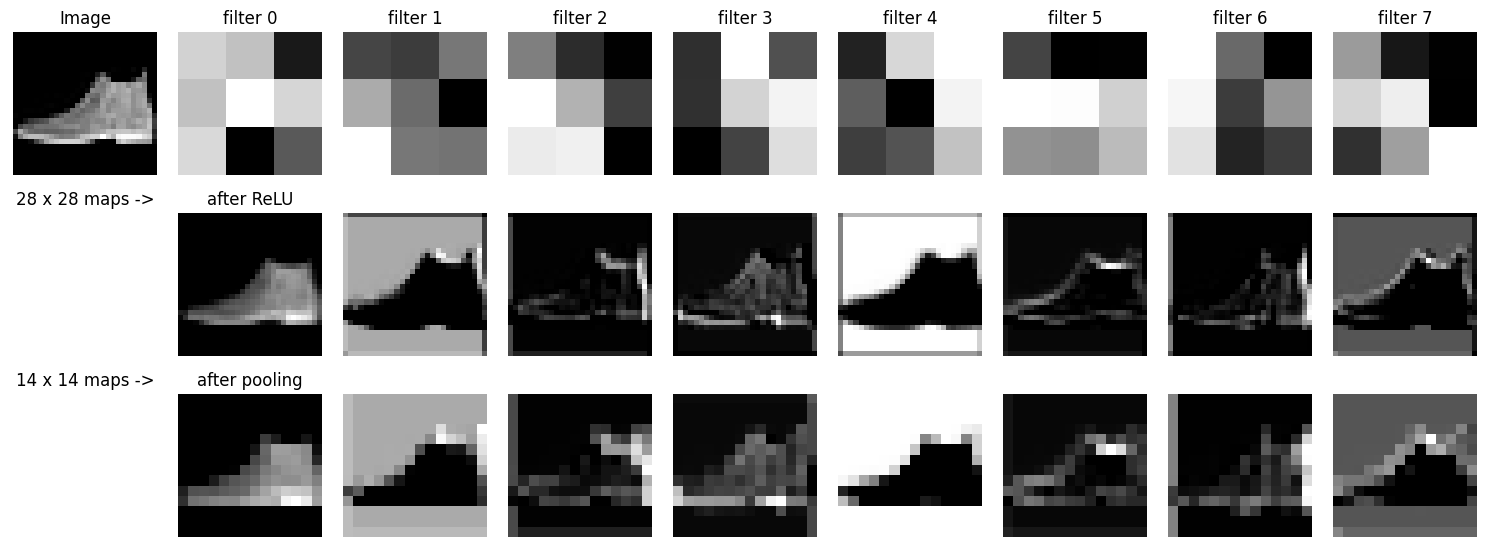

Test image 5 class: Trouser


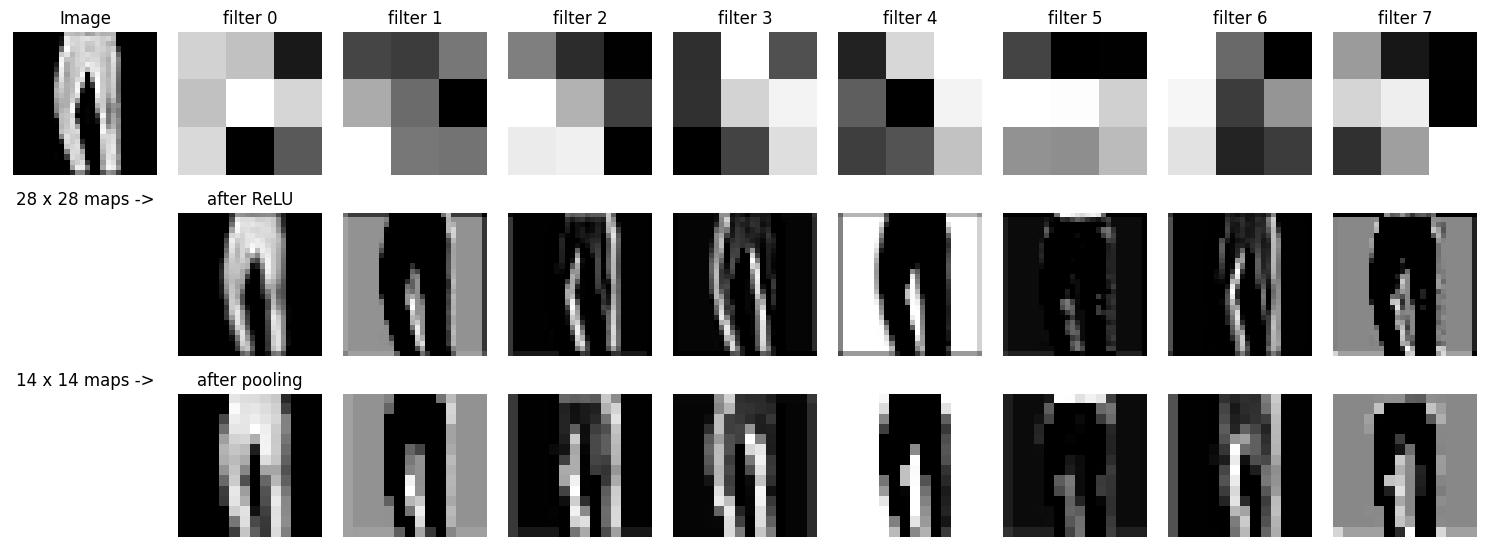

In [12]:
def show_feature_maps(model, image):
    model.eval()
    with torch.no_grad():
        x = image.unsqueeze(0).to(device)
        after_conv = model.relu(model.conv1(x)).squeeze(0).cpu()        # (8, 28, 28)
        after_pool = model.pool(model.relu(model.conv1(x))).squeeze(0).cpu()   # (8, 14, 14)
    filters = model.conv1.weight.detach().cpu()                         # (8, 1, 3, 3)
    fig, ax = plt.subplots(3, 9, figsize=(15, 5.5))
    ax[0, 0].imshow(image.squeeze(), cmap="gray"); ax[0, 0].set_title("Image")
    for k in range(8):
        ax[0, k + 1].imshow(filters[k, 0], cmap="gray"); ax[0, k + 1].set_title(f"filter {k}")
        ax[1, k + 1].imshow(after_conv[k], cmap="gray"); ax[1, k + 1].set_title("after ReLU" if k == 0 else "")
        ax[2, k + 1].imshow(after_pool[k], cmap="gray"); ax[2, k + 1].set_title("after pooling" if k == 0 else "")
    ax[1, 0].set_title("28 x 28 maps ->"); ax[2, 0].set_title("14 x 14 maps ->")
    for a in ax.ravel(): a.axis("off")
    plt.tight_layout(); plt.show()

# TODO 6.1 — show_feature_maps(model, ...) for two test images
print("Test image 0 class:", CLASSES[test_set[0][1]])
show_feature_maps(model, test_set[0][0])
print("Test image 5 class:", CLASSES[test_set[5][1]])
show_feature_maps(model, test_set[5][0])

# Task 6 answers:
# Q1 (what do some of the filters look like? what do the corresponding feature maps highlight in the image?):
# Answer: The learned 3 x 3 filters act as specialized low-level detectors: filter 0 (bright center) highlights
# the solid foreground body of the Ankle boot and Trouser; filter 2 (bright left, dark right) and filter 3
# (dark left, bright right) act as vertical-edge detectors highlighting the right/left contours of the boot
# heel and trouser legs; filter 5 (dark top, bright middle/bottom) acts as a horizontal-edge detector
# highlighting the boot's upper edge/sole and trouser waistband; filters 1 and 4 act as inverted background/
# silhouette detectors; and filters 6 and 7 pick up diagonal contours and fine edge transitions.
# Q2 (compare the maps before and after pooling: what changed and what stayed?):
# Answer: After 2 x 2 max pooling, the spatial resolution drops from 28 x 28 to 14 x 14 (appearing blockier
# with fine pixel details smoothed out), while the main contours, bright activation regions, and overall
# shape of the clothing item remain clearly preserved.


---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

### Before you submit

- [ ] Kernel &rarr; Restart & Run All, no errors.
- [ ] Every `TODO` is done and no `raise NotImplementedError` is left.
- [ ] Task 1: the first output number is worked out by hand, and "matches F.conv2d: True" is printed.
- [ ] Task 2: "matches F.max_pool2d: True" is printed.
- [ ] Task 3: the shapes and parameters are printed (the CNN has 9,098 parameters), and the normal network is counted.
- [ ] Task 5: the training curves are plotted and the test accuracy is printed once.
- [ ] Task 6: the feature maps of two images are shown.
- [ ] Written answers present as comments: 1 (Q1&ndash;Q2), 2 (Q1&ndash;Q2), 3 (Q1&ndash;Q2), 5 (Q1&ndash;Q2), 6 (Q1&ndash;Q2).
- [ ] Renamed to `Lab11_<yourCMSID>.ipynb`.

### One thing to take away

A CNN is made of a few simple operations that you have now written yourself: a **convolution** slides a
small learned filter over the image, **ReLU** keeps the detections, **max pooling** shrinks the maps, and a
**linear layer** turns the final maps into class scores. Because the filter is shared, the CNN needs far fewer
parameters than a normal network, and it finds a pattern wherever it appears.

</div>
